# Problem 1: Structural Mechanics

In [3]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=0)

np.set_printoptions(precision=4, suppress=True)

plt.rcParams.update({
    "figure.figsize": (6, 4),
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

In [4]:
# Helper functions
def build_K(n):
    K = 2 * np.eye(n) - np.eye(n, k=1) - np.eye(n, k=-1)
    K[-1, -1] = 1         
    return K

def build_b(n):
    b = np.zeros(n)
    b[-1] = 1
    return b

def build_u_star(n):
    return np.arange(1, n + 1, dtype=float)

In [5]:
# Function, gradient, and Hessian
def f(u, K, b):
    return 0.5 * u @ K @ u - b @ u

def grad_f(u, K, b):
    return K @ u - b

def hess_f(u, K, b):
    return K

### Task 3.2

In [6]:
def numerical_gradient(u, K, b, t=1e-6):
    n = len(u)
    g = np.zeros(n)
    for i in range(n):
        e = np.zeros(n)
        e[i] = 1.0                                       # i-th unit vector
        g[i] = (f(u + t * e, K, b) - f(u - t * e, K, b)) / (2 * t)
    return g


for n in range(1, 21):
    K, b = build_K(n), build_b(n)
    u = build_u_star(n) + rng.standard_normal(n)                    
    error = np.linalg.norm(numerical_gradient(u, K, b) - grad_f(u, K, b))
    print(f"{n:2d}   {error:.2e}")

 1   2.56e-11
 2   1.10e-10
 3   4.75e-10
 4   3.77e-10
 5   1.18e-09
 6   7.16e-10
 7   1.04e-09
 8   8.58e-10
 9   8.63e-09
10   7.97e-09
11   8.50e-09
12   1.44e-08
13   1.26e-08
14   1.06e-08
15   4.21e-09
16   2.72e-08
17   2.22e-08
18   3.93e-08
19   2.12e-08
20   5.08e-08


We observe the error is very small, the numerical solution is very close to the analytical one.

### Task 4.1    

#### (a) Gradient descent with: fixed step size, exact line search, backtracking line search

In [7]:
def exact_step(u, g, K, b):
    """Exact line search: minimiser of phi(alpha) = f(u - alpha*g).
    For a quadratic f this has the closed form alpha = g^T g / g^T H g."""
    H = hess_f(u, K, b)
    return (g @ g) / (g @ H @ g)

def backtracking_step(u, g, K, b, alpha0=1.0, rho=0.5, c=1e-4):
    """Backtracking line search (Algorithm 3.3) with d = -g:
    shrink alpha until the Armijo condition holds."""
    alpha = alpha0
    while f(u - alpha * g, K, b) > f(u, K, b) - c * alpha * (g @ g):
        alpha = rho * alpha
    return alpha

In [8]:
def gradient_descent(u0, K, b, step="constant", alpha=0.1,
                     eps=1e-6, max_iter=10000):
    u = u0.copy()
    history = {"u": [u.copy()], "f": [f(u, K, b)], "grad_norm": [], "alpha": []}

    for k in range(max_iter):
        g = grad_f(u, K, b)
        history["grad_norm"].append(np.linalg.norm(g))
        if np.linalg.norm(g) < eps:                      # stopping criterion
            break

        if step == "constant":
            alpha_k = alpha
        elif step == "exact":
            alpha_k = exact_step(u, g, K, b)
        elif step == "backtracking":
            alpha_k = backtracking_step(u, g, K, b)

        u = u - alpha_k * g                              # gradient step
        history["u"].append(u.copy())
        history["f"].append(f(u, K, b))
        history["alpha"].append(alpha_k)

    return u, history

#### (c) Experiments 

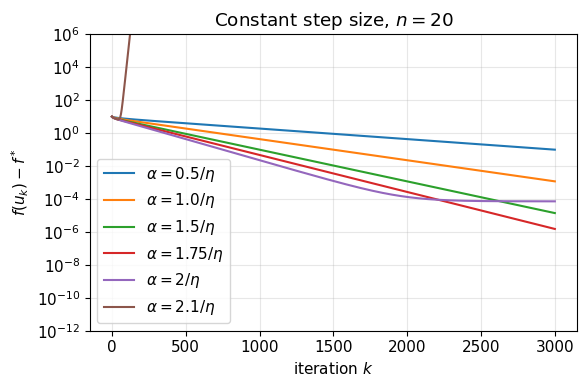

In [ ]:
# fixed step size experiments
n = 20
K, b, u_star = build_K(n), build_b(n), build_u_star(n)
f_star = f(u_star, K, b)
eta = np.linalg.eigvalsh(K).max()
u0 = np.zeros(n)

factors = [.5, 1.0, 1.5, 1.75, 2, 2.1]

plt.figure()
for c_ in factors:
    u, hist = gradient_descent(u0, K, b, step="constant", alpha=c_ / eta,
                               eps=1e-8, max_iter=3000)
    plt.semilogy(np.array(hist["f"]) - f_star, label=rf"$\alpha = {c_}/\eta$")
plt.ylim(1e-12, 1e6)                          
plt.xlabel("iteration $k$")
plt.ylabel(r"$f(u_k) - f^*$")
plt.title(f"Constant step size, $n = {n}$")
plt.legend()
plt.tight_layout()
plt.savefig("P1_GD_stepsizes.png", dpi=300)
plt.show()

  n      strategy  iterations  ||u - u*||
  3      constant         215    4.94e-06
  3         exact         112    3.04e-06
  3  backtracking         104    2.79e-06
 10      constant        2267    4.47e-05
 10         exact        1136    3.32e-05
 10  backtracking        1157    2.91e-05
 50      constant       20000    1.62e+00
 50         exact       20000    1.04e-02
 50  backtracking       20000    1.27e-02


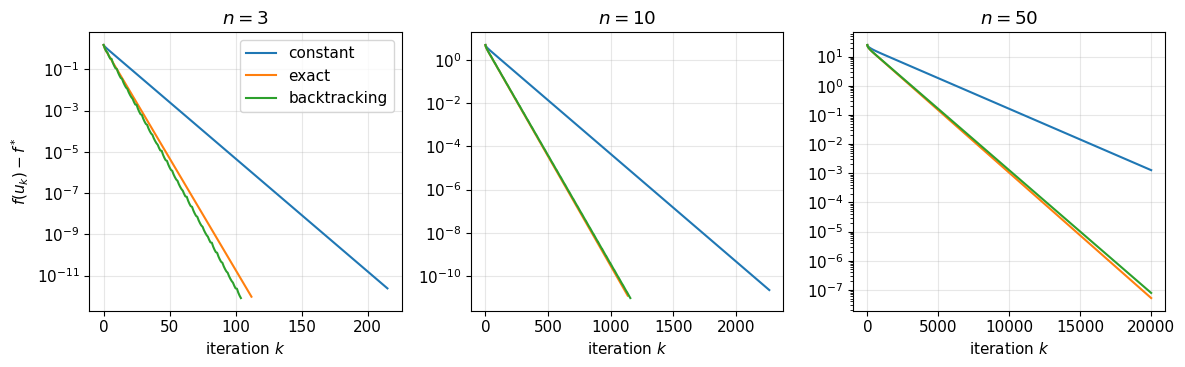

In [22]:
#three step size strategies for different n
ns = [3, 10, 50]
strategies = ["constant", "exact", "backtracking"]

fig, axes = plt.subplots(1, len(ns), figsize=(12, 3.8))
print(f"{'n':>3} {'strategy':>13} {'iterations':>11} {'||u - u*||':>11}")
for ax, n in zip(axes, ns):
    K, b, u_star = build_K(n), build_b(n), build_u_star(n)
    f_star = f(u_star, K, b)
    eta = np.linalg.eigvalsh(K).max()
    u0 = np.zeros(n)
    for step in strategies:
        u, hist = gradient_descent(u0, K, b, step=step, alpha=1 / eta,
                                   eps=1e-6, max_iter=20000)
        ax.semilogy(np.array(hist["f"]) - f_star, label=step)
        print(f"{n:3d} {step:>13} {len(hist['alpha']):11d} "
              f"{np.linalg.norm(u - u_star):11.2e}")
    ax.set_title(f"$n = {n}$")
    ax.set_xlabel("iteration $k$")
axes[0].set_ylabel(r"$f(u_k) - f^*$")
axes[0].legend()
plt.tight_layout()
plt.savefig("P1_GD_strategies.png", dpi=300)
plt.show()